# Exploratory Data Analysis — Graph-Vul

This notebook explores the Graph-Vul dataset at two levels:
1. **Raw text** — source code and CVE descriptions from `subset_cwe119.csv`
2. **Processed data** — PyG graphs, DeBERTa embeddings, and train/val/test splits

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from graph_vul.config import DATA_DIR, PROCESSED_DIR, SPLITS_DIR, SUBSET_CSV

sns.set_theme(style="whitegrid")
%matplotlib inline

## Part 1 — Raw Text EDA

### 1.1 Dataset Overview

In [2]:
df = pd.read_csv(SUBSET_CSV)
print(f"Total samples: {len(df)}")
print(f"\nClass distribution:")
counts = df["vul"].value_counts()
for label, count in counts.items():
    name = "vulnerable" if label == 1 else "benign"
    print(f"  {name} ({label}): {count} ({count / len(df) * 100:.1f}%)")

df.head()

Total samples: 1000

Class distribution:
  benign (0): 500 (50.0%)
  vulnerable (1): 500 (50.0%)


,sample_id,func_before,cve_id,cve_desc,vul
0,0,int32 WebContentsImpl::GetMaxPageID() {\n ret...,CVE-2013-6626,The WebContentsImpl::AttachInterstitialPage fu...,0
1,1,"static bool cmd_read_native_max(IDEState *s, u...",CVE-2014-9718,The (1) BMDMA and (2) AHCI HBA interfaces in t...,0
2,2,void RenderViewHostImpl::WasSwappedOut() {\n ...,CVE-2013-0840,Google Chrome before 24.0.1312.56 does not val...,0
3,3,void WaitForResizeComplete(WebContents* web_co...,CVE-2018-6121,Insufficient validation of input in Blink in G...,0
4,4,static inline int l2cap_config_req(struct l2ca...,CVE-2017-1000251,The native Bluetooth stack in the Linux Kernel...,1


### 1.2 Code Text Statistics

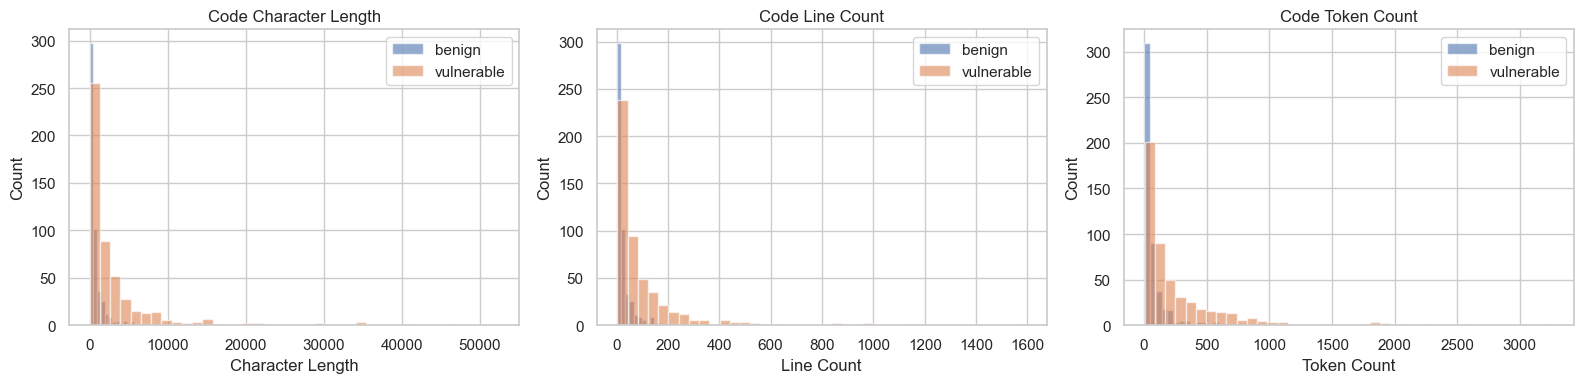

,code_char_len,code_line_count,code_token_count
count,1000.000000,1000.000000,1000.00000
mean,1976.126000,64.141000,174.13900
std,4387.976763,129.719089,330.92663
min,25.000000,2.000000,2.00000
25%,252.000000,10.000000,20.00000
50%,646.000000,21.500000,55.00000
75%,1819.500000,63.250000,179.00000
max,52461.000000,1595.000000,3269.00000


In [3]:
df["code_char_len"] = df["func_before"].str.len()
df["code_line_count"] = df["func_before"].str.count("\n") + 1
df["code_token_count"] = df["func_before"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
    axes,
    ["code_char_len", "code_line_count", "code_token_count"],
    ["Character Length", "Line Count", "Token Count"],
):
    for label, group in df.groupby("vul"):
        name = "vulnerable" if label == 1 else "benign"
        ax.hist(group[col], bins=40, alpha=0.6, label=name)
    ax.set_title(f"Code {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Count")
    ax.legend()
plt.tight_layout()
plt.show()

df[["code_char_len", "code_line_count", "code_token_count"]].describe()

### 1.3 CVE Description Statistics

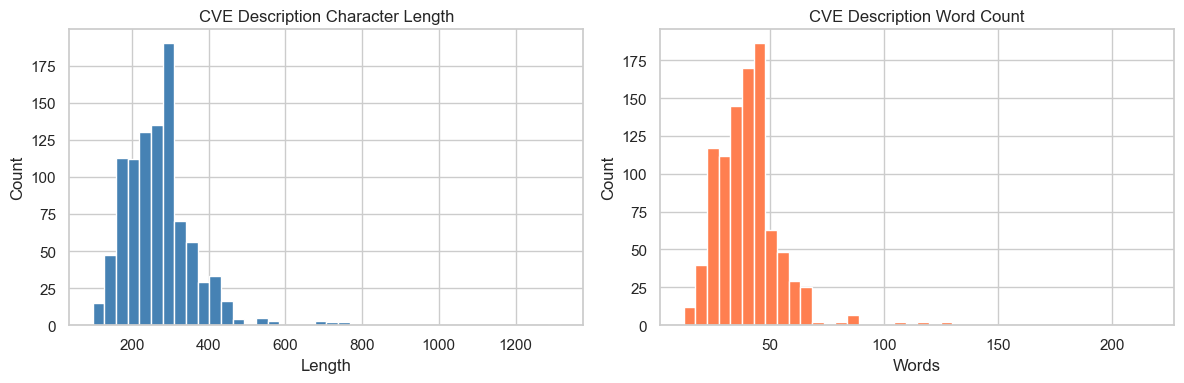

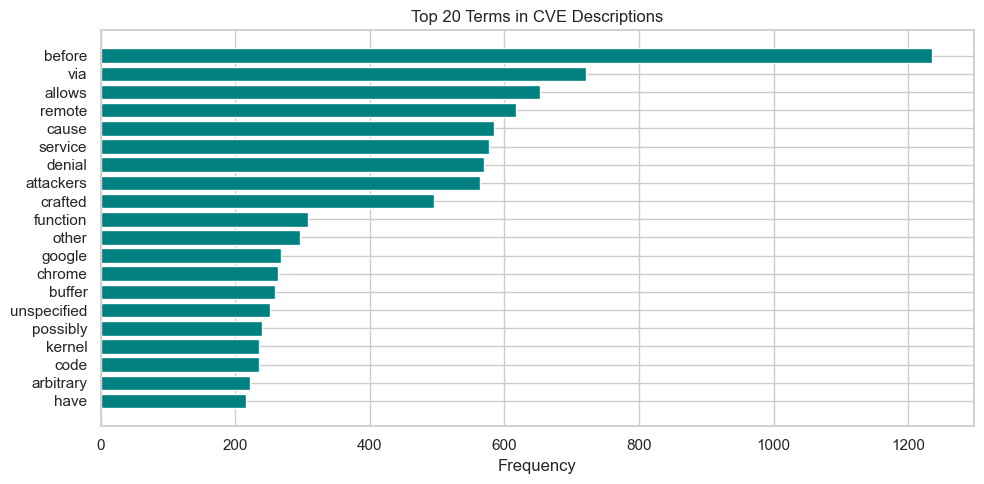

In [4]:
cve = df["cve_desc"].dropna()
df["cve_char_len"] = df["cve_desc"].str.len()
df["cve_word_count"] = df["cve_desc"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["cve_char_len"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("CVE Description Character Length")
axes[0].set_xlabel("Length")
axes[0].set_ylabel("Count")

axes[1].hist(df["cve_word_count"].dropna(), bins=40, color="coral", edgecolor="white")
axes[1].set_title("CVE Description Word Count")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

# Top-20 most frequent terms (excluding common stopwords)
stopwords = {"the", "a", "an", "in", "to", "of", "and", "is", "for", "on", "that", "with", "by", "as", "or", "it", "be", "this", "from", "are", "was", "at", "not", "which", "but", "its"}
all_words = " ".join(cve).lower().split()
filtered = [w for w in all_words if w not in stopwords and len(w) > 2]
top20 = Counter(filtered).most_common(20)

fig, ax = plt.subplots(figsize=(10, 5))
words, counts = zip(*top20)
ax.barh(words[::-1], counts[::-1], color="teal")
ax.set_title("Top 20 Terms in CVE Descriptions")
ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

## Part 2 — Processed Data EDA

### 2.1 Graph Structure Statistics

Loaded 1000 graphs


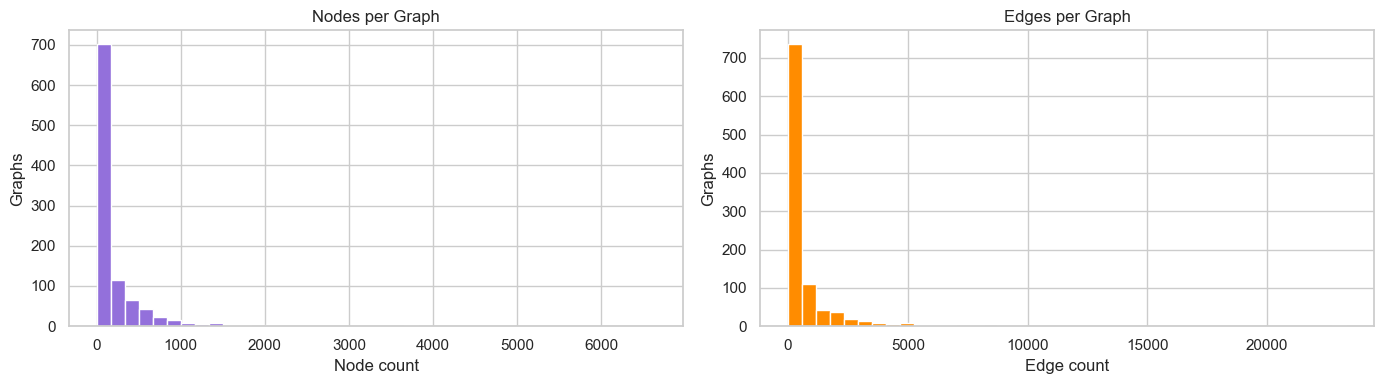

,nodes,edges
mean,213.725,742.084
median,50.500,117.500
min,8.000,8.000
max,6640.000,23298.000


In [5]:
import torch
from graph_vul.dataset.cpg_dataset import CPGDataset

dataset = CPGDataset()
print(f"Loaded {len(dataset)} graphs")

node_counts = []
edge_counts = []
labels = []
for i in range(len(dataset)):
    data = dataset[i]
    node_counts.append(data.num_nodes)
    edge_counts.append(data.edge_index.size(1))
    labels.append(int(data.y[0].item()))

node_counts = np.array(node_counts)
edge_counts = np.array(edge_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(node_counts, bins=40, color="mediumpurple", edgecolor="white")
axes[0].set_title("Nodes per Graph")
axes[0].set_xlabel("Node count")
axes[0].set_ylabel("Graphs")

axes[1].hist(edge_counts, bins=40, color="darkorange", edgecolor="white")
axes[1].set_title("Edges per Graph")
axes[1].set_xlabel("Edge count")
axes[1].set_ylabel("Graphs")
plt.tight_layout()
plt.show()

stats = pd.DataFrame({"nodes": node_counts, "edges": edge_counts})
stats.describe().loc[["mean", "50%", "min", "max"]].rename(index={"50%": "median"})

### 2.2 Edge Type Breakdown

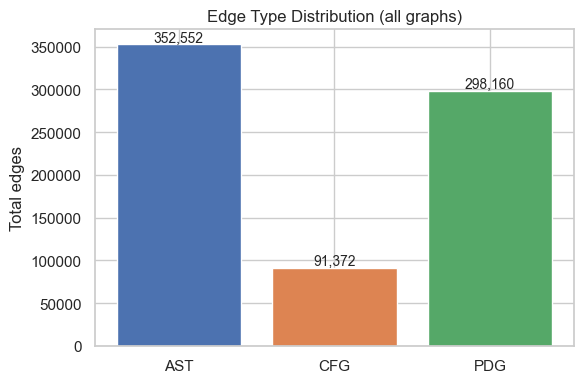

In [6]:
edge_type_names = {0: "AST", 1: "CFG", 2: "PDG"}
type_counts = Counter()
for i in range(len(dataset)):
    data = dataset[i]
    for t in data.edge_type.tolist():
        type_counts[t] += 1

names = [edge_type_names.get(k, f"type_{k}") for k in sorted(type_counts)]
values = [type_counts[k] for k in sorted(type_counts)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(names, values, color=["#4c72b0", "#dd8452", "#55a868"])
ax.set_title("Edge Type Distribution (all graphs)")
ax.set_ylabel("Total edges")
for i, v in enumerate(values):
    ax.text(i, v + max(values) * 0.01, f"{v:,}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()

### 2.3 Embedding Analysis

Node embedding dim: 768
  mean: 0.0025, std: 0.5615
CVE embedding dim:  768
  mean: 0.0155, std: 1.0180


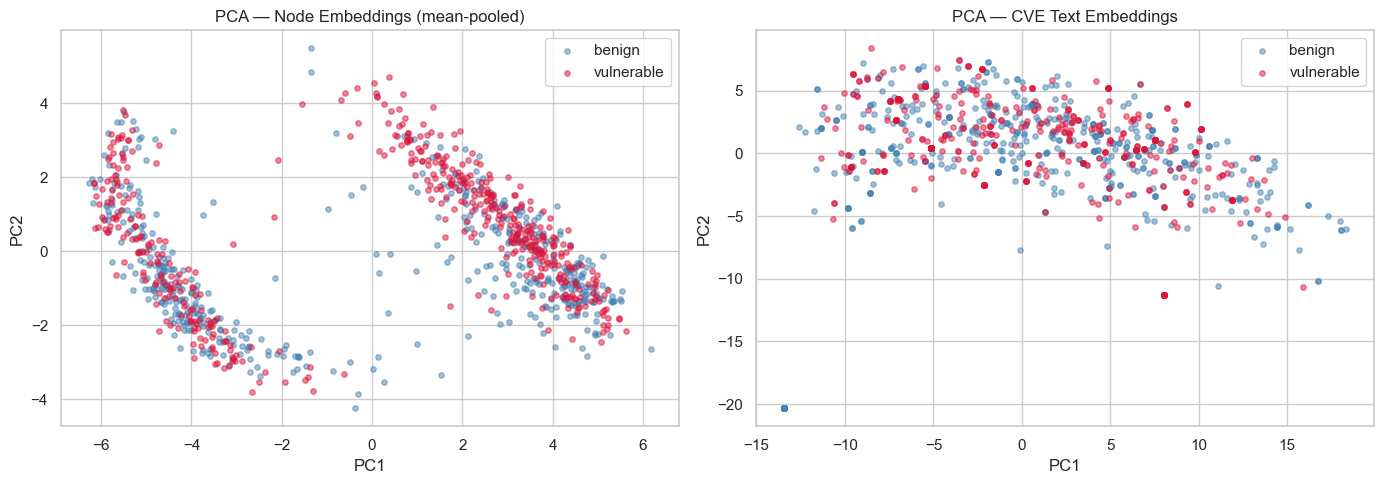

In [7]:
from sklearn.decomposition import PCA

# Collect graph-level embeddings: mean-pool node embeddings and CVE text vectors
node_emb_means = []
cve_embs = []
graph_labels = []
for i in range(len(dataset)):
    data = dataset[i]
    node_emb_means.append(data.x.mean(dim=0).numpy())
    cve_embs.append(data.text_vec.squeeze(0).numpy())
    graph_labels.append(int(data.y[0].item()))

node_emb_means = np.stack(node_emb_means)
cve_embs = np.stack(cve_embs)
graph_labels = np.array(graph_labels)

print(f"Node embedding dim: {node_emb_means.shape[1]}")
print(f"  mean: {node_emb_means.mean():.4f}, std: {node_emb_means.std():.4f}")
print(f"CVE embedding dim:  {cve_embs.shape[1]}")
print(f"  mean: {cve_embs.mean():.4f}, std: {cve_embs.std():.4f}")

# PCA projections
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, embs, title in zip(
    axes,
    [node_emb_means, cve_embs],
    ["Node Embeddings (mean-pooled)", "CVE Text Embeddings"],
):
    proj = PCA(n_components=2).fit_transform(embs)
    for label, color, name in [(0, "steelblue", "benign"), (1, "crimson", "vulnerable")]:
        mask = graph_labels == label
        ax.scatter(proj[mask, 0], proj[mask, 1], alpha=0.5, s=15, c=color, label=name)
    ax.set_title(f"PCA — {title}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()

plt.tight_layout()
plt.show()

### 2.4 Train / Val / Test Split Statistics

      total vulnerable benign vul_ratio
train   700        350    350     50.0%
val     150         75     75     50.0%
test    150         75     75     50.0%


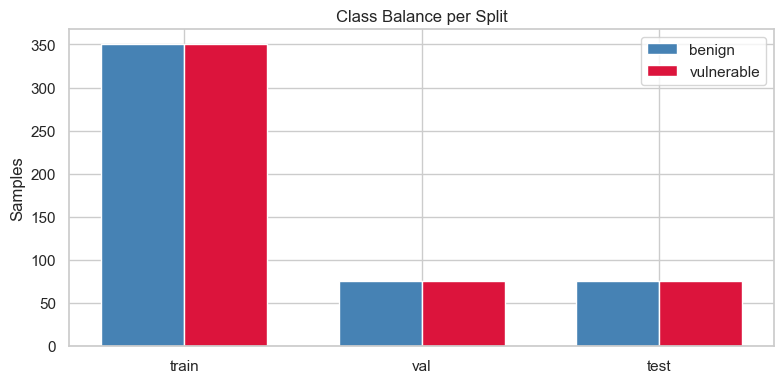

In [8]:
split_stats = {}
for split_name in ["train", "val", "test"]:
    ids = json.loads((SPLITS_DIR / f"{split_name}.json").read_text())
    split_df = df[df["sample_id"].isin(ids)]
    vul_count = split_df["vul"].sum()
    total = len(split_df)
    split_stats[split_name] = {
        "total": total,
        "vulnerable": int(vul_count),
        "benign": total - int(vul_count),
        "vul_ratio": f"{vul_count / total * 100:.1f}%" if total > 0 else "N/A",
    }

split_table = pd.DataFrame(split_stats).T
print(split_table.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(split_stats))
width = 0.35
ax.bar(x - width / 2, split_table["benign"], width, label="benign", color="steelblue")
ax.bar(x + width / 2, split_table["vulnerable"], width, label="vulnerable", color="crimson")
ax.set_xticks(x)
ax.set_xticklabels(split_table.index)
ax.set_ylabel("Samples")
ax.set_title("Class Balance per Split")
ax.legend()
plt.tight_layout()
plt.show()

### 2.5 Sample Graph Visualization

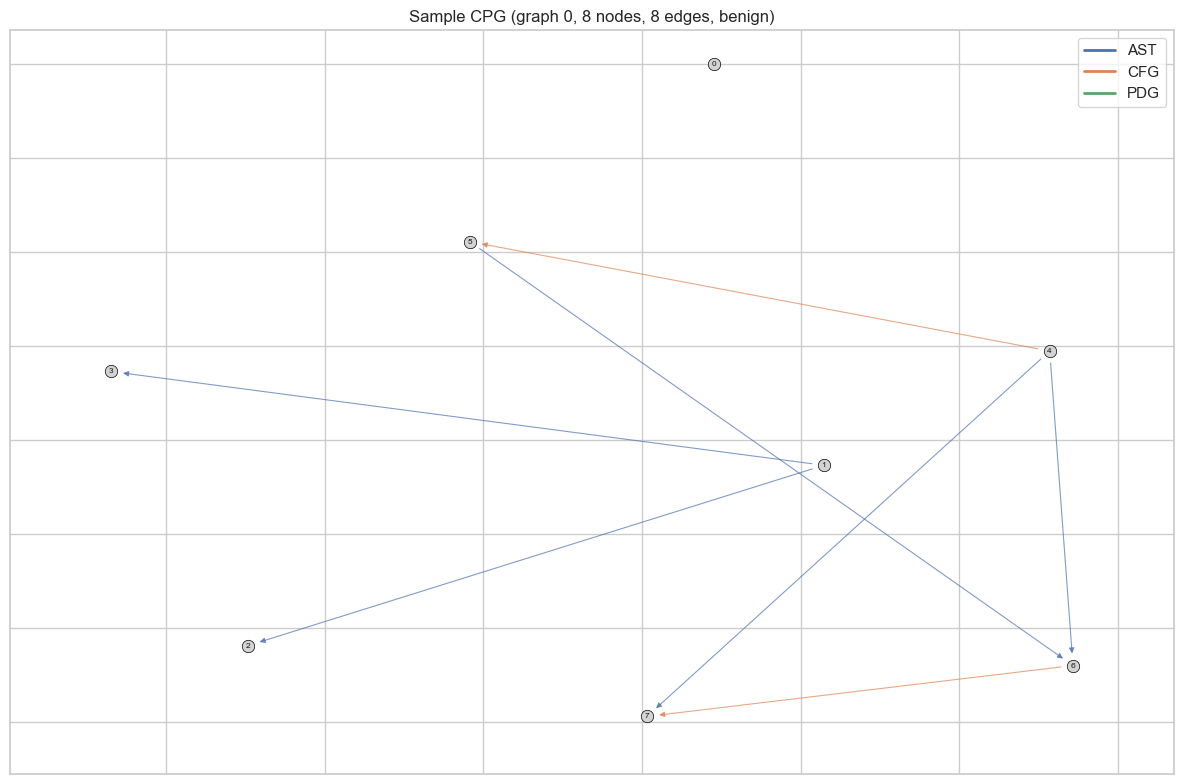

In [9]:
import networkx as nx

sample = dataset[0]
edge_color_map = {0: "#4c72b0", 1: "#dd8452", 2: "#55a868"}  # AST, CFG, PDG

G = nx.DiGraph()
G.add_nodes_from(range(sample.num_nodes))
edge_colors = []
for i in range(sample.edge_index.size(1)):
    src = sample.edge_index[0, i].item()
    dst = sample.edge_index[1, i].item()
    etype = sample.edge_type[i].item()
    G.add_edge(src, dst, edge_type=etype)
    edge_colors.append(edge_color_map.get(etype, "gray"))

fig, ax = plt.subplots(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42, k=2.0)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=80, node_color="lightgray", edgecolors="black", linewidths=0.5)
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, arrows=True, arrowsize=8, width=0.8, alpha=0.7)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="#4c72b0", lw=2, label="AST"),
    Line2D([0], [0], color="#dd8452", lw=2, label="CFG"),
    Line2D([0], [0], color="#55a868", lw=2, label="PDG"),
]
ax.legend(handles=legend_elements, loc="upper right")
label_str = "vulnerable" if sample.y[0].item() == 1 else "benign"
ax.set_title(f"Sample CPG (graph 0, {sample.num_nodes} nodes, {sample.edge_index.size(1)} edges, {label_str})")
plt.tight_layout()
plt.show()

## Deeper Structural EDA and Split Diagnostics

This section checks whether graph structure carries label signal beyond basic sanity checks, whether the train/val/test splits are matched in graph complexity, and how informative the graph and CVE text embeddings are quantitatively.

How to read this section:
- Persistent label differences in graph size or edge-type composition may reflect meaningful vulnerability structure, but they can also become shortcut features.
- Split-level shifts in graph complexity can make one split systematically easier or harder even when label balance is perfect.
- Embedding diagnostics complement PCA visuals with metrics that are easier to compare across modalities.


In [10]:
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EDGE_TYPE_NAMES = globals().get("edge_type_names", {0: "AST", 1: "CFG", 2: "PDG"})
LABEL_NAME_MAP = {0: "benign", 1: "vulnerable"}
PLOT_COLORS = {
    "benign": "steelblue",
    "vulnerable": "crimson",
    "train": "#4c72b0",
    "val": "#dd8452",
    "test": "#55a868",
    "unknown": "gray",
}


def safe_graph_label(data):
    y = getattr(data, "y", None)
    if y is None:
        return np.nan
    if hasattr(y, "numel") and y.numel() > 0:
        return int(float(y.reshape(-1)[0].item()))
    try:
        return int(y)
    except Exception:
        return np.nan


def format_label_name(label):
    if pd.isna(label):
        return "unknown"
    try:
        return LABEL_NAME_MAP.get(int(label), str(label))
    except Exception:
        return str(label)


def coerce_series_to_str_index(values):
    return pd.Index([str(v) for v in values])


def resolve_split_lookup(splits_dir=None):
    lookup = {}
    base_dir = Path(splits_dir) if splits_dir is not None else globals().get("SPLITS_DIR")
    if base_dir is None:
        print("Note: split directory is unavailable; split-dependent analyses will use 'unknown'.")
        return lookup

    for split_name in ["train", "val", "test"]:
        split_path = Path(base_dir) / f"{split_name}.json"
        if not split_path.exists():
            continue
        try:
            split_ids = json.loads(split_path.read_text())
        except Exception as exc:
            print(f"Warning: failed to read {split_path}: {exc}")
            continue
        for sample_id in split_ids:
            lookup[str(sample_id)] = split_name
    return lookup


def lookup_raw_row(raw_df=None, sample_id=None, fallback_idx=None):
    if raw_df is None or len(raw_df) == 0:
        return None

    if sample_id is not None and "sample_id" in raw_df.columns:
        matches = raw_df.loc[coerce_series_to_str_index(raw_df["sample_id"]) == str(sample_id)]
        if len(matches) > 0:
            return matches.iloc[0]

    if fallback_idx is not None and 0 <= fallback_idx < len(raw_df):
        return raw_df.iloc[fallback_idx]

    return None


def get_text_lengths(row_like):
    if row_like is None:
        return np.nan, np.nan

    for key in ["cve_desc", "cve_description", "description", "text", "cve_text"]:
        if key in row_like and pd.notna(row_like[key]):
            text = str(row_like[key])
            return len(text), len(text.split())
    return np.nan, np.nan


def infer_edge_type_counts(edge_type_tensor, edge_type_names=None):
    edge_type_names = edge_type_names or EDGE_TYPE_NAMES
    counts = {"ast_edges": 0, "cfg_edges": 0, "pdg_edges": 0}
    if edge_type_tensor is None:
        return counts

    try:
        edge_values = edge_type_tensor.detach().cpu().reshape(-1).tolist()
    except Exception:
        edge_values = list(edge_type_tensor)

    for edge_value in edge_values:
        edge_name = edge_type_names.get(int(edge_value), str(edge_value)).upper()
        if edge_name == "AST":
            counts["ast_edges"] += 1
        elif edge_name == "CFG":
            counts["cfg_edges"] += 1
        elif edge_name == "PDG":
            counts["pdg_edges"] += 1
    return counts


def extract_graph_structural_features(dataset, raw_df=None, splits_dir=None, edge_type_names=None):
    edge_type_names = edge_type_names or EDGE_TYPE_NAMES
    split_lookup = resolve_split_lookup(splits_dir=splits_dir)
    metadata = getattr(dataset, "_metadata", None)
    rows = []

    for sample_idx in range(len(dataset)):
        data = dataset[sample_idx]
        metadata_row = metadata.iloc[sample_idx] if metadata is not None and sample_idx < len(metadata) else None
        sample_id = metadata_row.get("sample_id") if metadata_row is not None and "sample_id" in metadata_row else sample_idx
        raw_row = lookup_raw_row(raw_df=raw_df, sample_id=sample_id, fallback_idx=sample_idx)

        num_nodes = int(getattr(data, "num_nodes", data.x.size(0) if hasattr(data, "x") else 0))
        num_edges = int(data.edge_index.size(1)) if getattr(data, "edge_index", None) is not None else 0
        label = metadata_row.get("vul") if metadata_row is not None and "vul" in metadata_row else safe_graph_label(data)
        edge_counts = infer_edge_type_counts(getattr(data, "edge_type", None), edge_type_names=edge_type_names)
        char_len, word_len = get_text_lengths(raw_row if raw_row is not None else metadata_row)

        row = {
            "sample_idx": sample_idx,
            "sample_id": sample_id,
            "label": int(label) if pd.notna(label) else np.nan,
            "label_name": format_label_name(label),
            "split": split_lookup.get(str(sample_id), "unknown"),
            "num_nodes": num_nodes,
            "num_edges": num_edges,
            **edge_counts,
            "ast_ratio": edge_counts["ast_edges"] / max(num_edges, 1),
            "cfg_ratio": edge_counts["cfg_edges"] / max(num_edges, 1),
            "pdg_ratio": edge_counts["pdg_edges"] / max(num_edges, 1),
            "edge_density_like": num_edges / max(num_nodes, 1),
            "cve_text_len_chars": char_len,
            "cve_text_len_words": word_len,
        }
        rows.append(row)

    structural_df = pd.DataFrame(rows)
    numeric_cols = [
        "label",
        "num_nodes",
        "num_edges",
        "ast_edges",
        "cfg_edges",
        "pdg_edges",
        "ast_ratio",
        "cfg_ratio",
        "pdg_ratio",
        "edge_density_like",
        "cve_text_len_chars",
        "cve_text_len_words",
    ]
    for col in numeric_cols:
        if col in structural_df.columns:
            structural_df[col] = pd.to_numeric(structural_df[col], errors="coerce")
    return structural_df


def summarize_by_group(dataframe, group_col, feature_stats):
    available = {col: stats for col, stats in feature_stats.items() if col in dataframe.columns}
    if group_col not in dataframe.columns or not available:
        return pd.DataFrame()
    summary = dataframe.groupby(group_col).agg(available)
    summary.columns = [f"{feature}_{stat}" for feature, stat in summary.columns]
    return summary.reset_index()


def plot_feature_by_group(dataframe, feature, group_col, bins=30, group_order=None, title=None, xlabel=None):
    if feature not in dataframe.columns or group_col not in dataframe.columns:
        print(f"Skipping plot for {feature}: missing column.")
        return None, None

    values = dataframe[feature].dropna()
    if values.empty:
        print(f"Skipping plot for {feature}: no non-null values.")
        return None, None

    if group_order is None:
        group_order = [g for g in dataframe[group_col].dropna().unique()]

    fig, ax = plt.subplots(figsize=(7, 4))
    for group_name in group_order:
        group_values = dataframe.loc[dataframe[group_col] == group_name, feature].dropna()
        if group_values.empty:
            continue
        color_key = str(group_name)
        color = PLOT_COLORS.get(color_key, PLOT_COLORS.get(str(group_name).lower(), None))
        ax.hist(group_values, bins=bins, alpha=0.45, label=str(group_name), color=color, edgecolor="white")

    ax.set_title(title or f"{feature} by {group_col}")
    ax.set_xlabel(xlabel or feature)
    ax.set_ylabel("Count")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return fig, ax


def plot_ratio_boxplots_by_label(dataframe, ratio_features):
    available_features = [feature for feature in ratio_features if feature in dataframe.columns]
    if not available_features:
        print("Skipping ratio boxplots: no requested ratio columns are available.")
        return None, None

    label_order = [0, 1]
    fig, axes = plt.subplots(1, len(available_features), figsize=(5 * len(available_features), 4))
    if len(available_features) == 1:
        axes = [axes]

    for ax, feature in zip(axes, available_features):
        grouped_values = [dataframe.loc[dataframe["label"] == label, feature].dropna().values for label in label_order]
        ax.boxplot(grouped_values, tick_labels=[LABEL_NAME_MAP[label] for label in label_order], patch_artist=True)
        for patch, label in zip(ax.artists, label_order):
            patch.set_facecolor(PLOT_COLORS[LABEL_NAME_MAP[label]])
        ax.set_title(feature)
        ax.set_ylabel("Ratio")
        ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()
    return fig, axes


def collect_embedding_views(dataset):
    node_embedding_rows = []
    text_embedding_rows = []
    labels = []

    for sample_idx in range(len(dataset)):
        data = dataset[sample_idx]
        if getattr(data, "x", None) is not None:
            node_embedding_rows.append(data.x.detach().cpu().float().mean(dim=0).numpy())
        else:
            node_embedding_rows.append(None)

        if getattr(data, "text_vec", None) is not None:
            text_embedding_rows.append(data.text_vec.detach().cpu().float().reshape(-1).numpy())
        else:
            text_embedding_rows.append(None)

        labels.append(safe_graph_label(data))

    node_embedding_rows = np.stack(node_embedding_rows) if all(v is not None for v in node_embedding_rows) else None
    text_embedding_rows = np.stack(text_embedding_rows) if all(v is not None for v in text_embedding_rows) else None
    return node_embedding_rows, text_embedding_rows, np.asarray(labels)


def ensure_embedding_inputs(dataset, fallback_labels=None):
    node_array = globals().get("node_emb_means")
    text_array = globals().get("cve_embs")
    label_array = globals().get("graph_labels")

    expected_len = len(dataset)
    node_ok = isinstance(node_array, np.ndarray) and node_array.ndim == 2 and node_array.shape[0] == expected_len
    text_ok = isinstance(text_array, np.ndarray) and text_array.ndim == 2 and text_array.shape[0] == expected_len
    label_ok = isinstance(label_array, np.ndarray) and label_array.shape[0] == expected_len

    if node_ok and text_ok and label_ok:
        return node_array, text_array, label_array.astype(int)

    print("Recomputing embedding matrices from the dataset because cached notebook variables are missing or mismatched.")
    node_array, text_array, label_array = collect_embedding_views(dataset)
    if label_array is None and fallback_labels is not None:
        label_array = np.asarray(fallback_labels)
    return node_array, text_array, label_array.astype(int)


def compute_nn_agreement(embeddings, labels):
    if embeddings is None or len(embeddings) < 2:
        return np.nan
    nn = NearestNeighbors(n_neighbors=2)
    nn.fit(embeddings)
    neighbor_indices = nn.kneighbors(embeddings, return_distance=False)[:, 1]
    return float(np.mean(labels == labels[neighbor_indices]))


def compute_embedding_diagnostics(embeddings, labels, random_state=42):
    if embeddings is None:
        return None

    X = np.asarray(embeddings)
    y = np.asarray(labels).astype(int)
    valid_mask = np.isfinite(X).all(axis=1) & np.isfinite(y)
    X = X[valid_mask]
    y = y[valid_mask]

    if X.ndim != 2 or len(X) == 0:
        return None

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=min(2, X_scaled.shape[0], X_scaled.shape[1]))
    projection = pca.fit_transform(X_scaled)
    explained = list(pca.explained_variance_ratio_)
    while len(explained) < 2:
        explained.append(np.nan)

    if len(np.unique(y)) > 1 and len(X_scaled) > 2:
        try:
            silhouette = float(silhouette_score(X_scaled, y))
        except Exception:
            silhouette = np.nan
    else:
        silhouette = np.nan

    centroid_distance = np.nan
    if len(np.unique(y)) == 2:
        class_values = sorted(np.unique(y))
        centroid_a = X_scaled[y == class_values[0]].mean(axis=0)
        centroid_b = X_scaled[y == class_values[1]].mean(axis=0)
        centroid_distance = float(np.linalg.norm(centroid_a - centroid_b))

    logistic_acc = np.nan
    logistic_auc = np.nan
    logistic_f1 = np.nan
    class_counts = pd.Series(y).value_counts()
    if len(class_counts) == 2 and class_counts.min() >= 2:
        n_splits = min(5, int(class_counts.min()))
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        clf = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, solver="liblinear", random_state=random_state),
        )
        pred_labels = cross_val_predict(clf, X, y, cv=cv, method="predict")
        pred_probs = cross_val_predict(clf, X, y, cv=cv, method="predict_proba")[:, 1]
        logistic_acc = float(accuracy_score(y, pred_labels))
        logistic_auc = float(roc_auc_score(y, pred_probs))
        logistic_f1 = float(f1_score(y, pred_labels))

    diagnostics = {
        "dim": int(X.shape[1]),
        "pc1_var": float(explained[0]) if pd.notna(explained[0]) else np.nan,
        "pc2_var": float(explained[1]) if pd.notna(explained[1]) else np.nan,
        "silhouette": silhouette,
        "centroid_distance": centroid_distance,
        "logistic_acc": logistic_acc,
        "logistic_auc": logistic_auc,
        "logistic_f1": logistic_f1,
        "nn_agreement": compute_nn_agreement(X_scaled, y),
        "projection": projection,
        "labels": y,
    }
    return diagnostics


### A. Per-Graph Structural Feature Table

This table creates one structural summary row per graph. It is the backbone for the remaining analyses because it turns the PyG objects into tabular features that are easy to group, compare, and inspect.

Why it matters for vulnerability modeling:
- It exposes graph size and edge-type composition at the sample level.
- It lets us compare benign and vulnerable graphs without relying only on global counts.
- It makes it easy to test whether graph complexity differs across train/val/test.

Interpretation:
- Large shifts in `num_nodes`, `num_edges`, or edge-type ratios can indicate real structural differences.
- If these shifts are too strong, they may also act as shortcut features that a model can exploit without learning richer program semantics.


In [11]:
structural_features_df = extract_graph_structural_features(
    dataset=dataset,
    raw_df=globals().get("df"),
    splits_dir=globals().get("SPLITS_DIR"),
    edge_type_names=EDGE_TYPE_NAMES,
)

print(f"Structural feature table shape: {structural_features_df.shape}")
print("Columns:", list(structural_features_df.columns))
display(structural_features_df.head())

structural_numeric_summary = structural_features_df.select_dtypes(include=[np.number]).describe().T
structural_numeric_summary = structural_numeric_summary[[col for col in ["mean", "50%", "std", "min", "max"] if col in structural_numeric_summary.columns]]
structural_numeric_summary = structural_numeric_summary.rename(columns={"50%": "median"})
display(structural_numeric_summary.round(3))


Structural feature table shape: (1000, 16)
Columns: ['sample_idx', 'sample_id', 'label', 'label_name', 'split', 'num_nodes', 'num_edges', 'ast_edges', 'cfg_edges', 'pdg_edges', 'ast_ratio', 'cfg_ratio', 'pdg_ratio', 'edge_density_like', 'cve_text_len_chars', 'cve_text_len_words']


,sample_idx,sample_id,label,label_name,split,num_nodes,num_edges,ast_edges,cfg_edges,pdg_edges,ast_ratio,cfg_ratio,pdg_ratio,edge_density_like,cve_text_len_chars,cve_text_len_words
0,0,0,0,benign,train,8,8,5,3,0,0.625000,0.375000,0.000000,1.000000,297.0,34.0
1,1,1,0,benign,val,79,204,105,25,74,0.514706,0.122549,0.362745,2.582278,381.0,60.0
2,2,2,0,benign,train,8,8,5,3,0,0.625000,0.375000,0.000000,1.000000,147.0,22.0
3,3,3,0,benign,train,70,161,95,21,45,0.590062,0.130435,0.279503,2.300000,164.0,25.0
4,4,4,1,vulnerable,train,370,1060,563,136,361,0.531132,0.128302,0.340566,2.864865,283.0,44.0


,mean,median,std,min,max
sample_idx,499.500,499.500,288.819,0.000,999.000
sample_id,499.500,499.500,288.819,0.000,999.000
label,0.500,0.500,0.500,0.000,1.000
num_nodes,213.725,50.500,461.942,8.000,6640.000
num_edges,742.084,117.500,2026.803,8.000,23298.000
ast_edges,352.552,65.500,846.366,5.000,12695.000
cfg_edges,91.372,16.000,219.110,3.000,3163.000
pdg_edges,298.160,38.000,1049.528,0.000,14704.000
ast_ratio,0.566,0.563,0.060,0.280,0.682
cfg_ratio,0.233,0.154,0.120,0.066,0.385


### B. Structural Feature Comparison by Label

These cells check whether vulnerable and benign graphs differ in graph size, graph density proxy, or edge-type mix.

Why it matters for graph vulnerability modeling:
- If one class systematically has larger or denser graphs, the model may partially solve the task from complexity alone.
- Edge-type ratios can reveal whether vulnerable functions carry distinctive AST / CFG / PDG structure.

Interpretation:
- Overlapping histograms suggest weak separation from that feature alone.
- Clear shifts in medians or boxplots suggest the feature may carry class signal.
- Strong class separation is informative, but it is also a sign to watch for shortcut learning.


,label_name,num_nodes_mean,num_nodes_median,num_nodes_std,num_edges_mean,num_edges_median,num_edges_std,edge_density_like_mean,edge_density_like_median,edge_density_like_std,ast_ratio_mean,ast_ratio_median,ast_ratio_std,cfg_ratio_mean,cfg_ratio_median,cfg_ratio_std,pdg_ratio_mean,pdg_ratio_median,pdg_ratio_std
0,benign,89.27,26.5,138.0250,251.496,54.0,442.4263,1.8550,2.0352,0.8520,0.5770,0.5879,0.0522,0.2485,0.1783,0.1199,0.1745,0.2462,0.1676
1,vulnerable,338.18,110.0,614.0996,1232.672,281.5,2747.0053,2.3144,2.6261,1.1058,0.5546,0.5441,0.0657,0.2172,0.1433,0.1186,0.2282,0.3184,0.1770


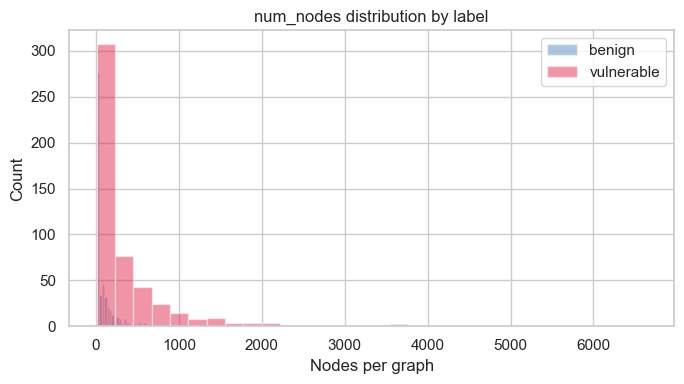

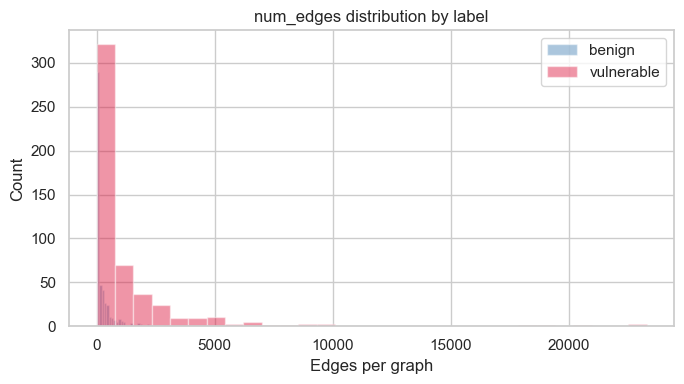

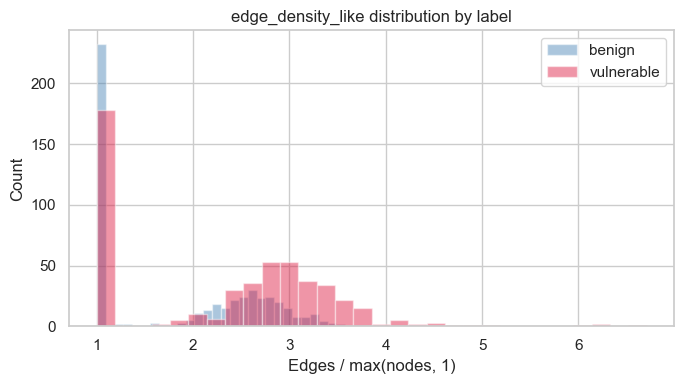

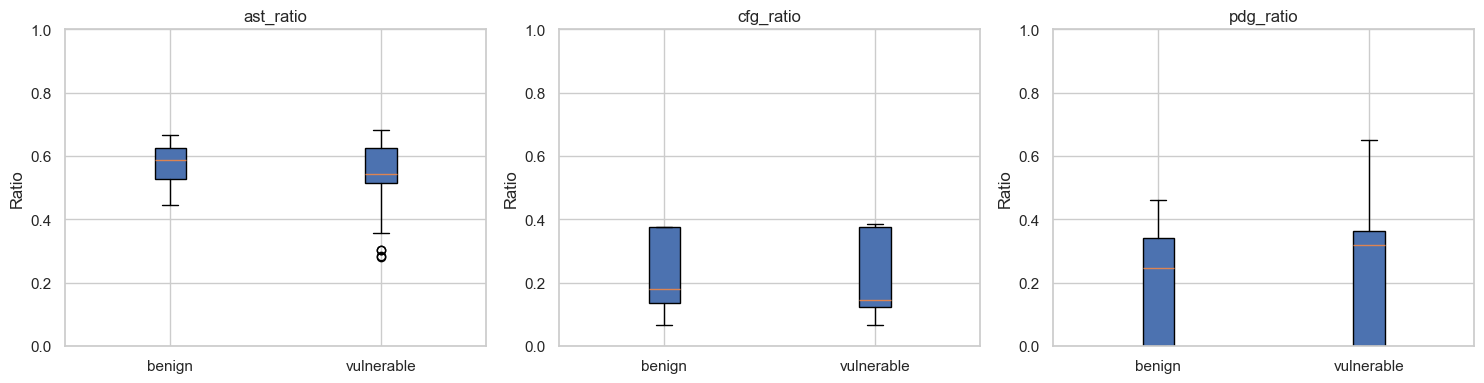

(<Figure size 1500x400 with 3 Axes>,
 array([<Axes: title={'center': 'ast_ratio'}, ylabel='Ratio'>,
        <Axes: title={'center': 'cfg_ratio'}, ylabel='Ratio'>,
        <Axes: title={'center': 'pdg_ratio'}, ylabel='Ratio'>],
       dtype=object))

In [12]:
label_feature_stats = {
    "num_nodes": ["mean", "median", "std"],
    "num_edges": ["mean", "median", "std"],
    "edge_density_like": ["mean", "median", "std"],
    "ast_ratio": ["mean", "median", "std"],
    "cfg_ratio": ["mean", "median", "std"],
    "pdg_ratio": ["mean", "median", "std"],
}

label_summary_table = summarize_by_group(structural_features_df, "label_name", label_feature_stats).round(4)
display(label_summary_table)

for feature, xlabel in [
    ("num_nodes", "Nodes per graph"),
    ("num_edges", "Edges per graph"),
    ("edge_density_like", "Edges / max(nodes, 1)"),
]:
    plot_feature_by_group(
        structural_features_df,
        feature=feature,
        group_col="label_name",
        group_order=["benign", "vulnerable"],
        bins=30,
        title=f"{feature} distribution by label",
        xlabel=xlabel,
    )

plot_ratio_boxplots_by_label(structural_features_df, ["ast_ratio", "cfg_ratio", "pdg_ratio"])


### C. Split Comparability Diagnostics

These diagnostics go beyond label counts and ask whether the train, validation, and test splits have similar graph complexity.

Why it matters for graph vulnerability modeling:
- A split with much larger or denser graphs can change optimization difficulty, memory pressure, and generalization behavior.
- Balanced labels do not guarantee balanced structural difficulty.

Interpretation:
- Similar split summaries support a fairer evaluation setup.
- Large differences in medians or edge-type composition suggest that one split may be structurally easier or harder.
- The printed warning uses simple heuristics to flag large shifts, not a formal hypothesis test.


,split,count,vulnerable_fraction,num_nodes_mean,num_nodes_median,num_edges_mean,num_edges_median,edge_density_like_mean,edge_density_like_median,ast_ratio_mean,cfg_ratio_mean,pdg_ratio_mean
0,test,150,0.5,228.0867,69.0,798.8267,172.0,2.1626,2.4510,0.5632,0.2214,0.2154
1,train,700,0.5,202.0929,44.0,671.2343,96.5,2.0469,2.2624,0.5678,0.2372,0.1950
2,val,150,0.5,253.6467,73.0,1015.9733,175.0,2.1830,2.4101,0.5590,0.2242,0.2169


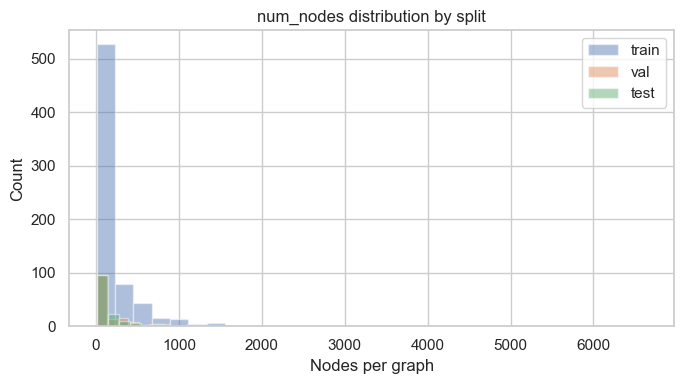

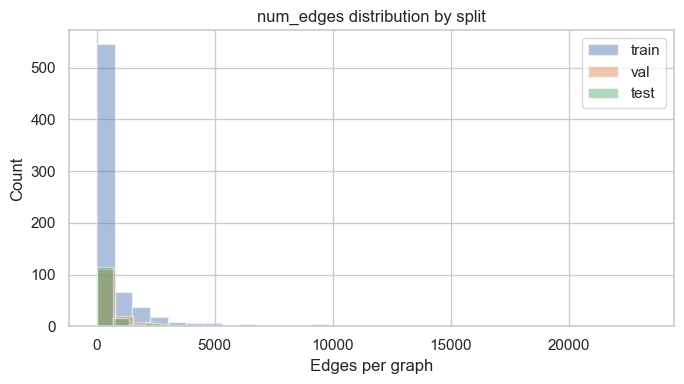

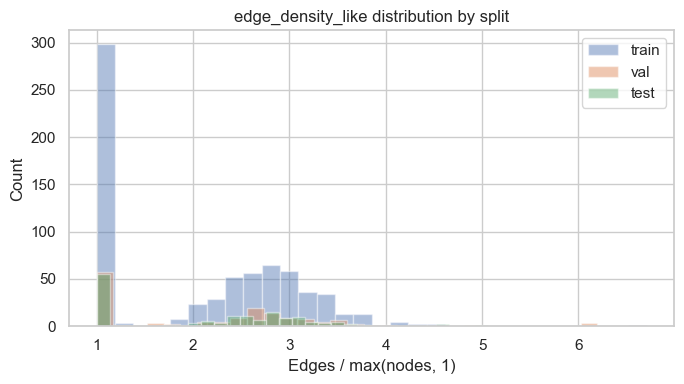

In [13]:
split_feature_stats = {
    "label": ["count", "mean"],
    "num_nodes": ["mean", "median"],
    "num_edges": ["mean", "median"],
    "edge_density_like": ["mean", "median"],
    "ast_ratio": ["mean"],
    "cfg_ratio": ["mean"],
    "pdg_ratio": ["mean"],
}

split_summary_table = summarize_by_group(structural_features_df, "split", split_feature_stats)
if not split_summary_table.empty:
    split_summary_table = split_summary_table.rename(
        columns={"label_count": "count", "label_mean": "vulnerable_fraction"}
    ).round(4)
    display(split_summary_table)
else:
    print("Split summary could not be computed because split information is unavailable.")

available_splits = [split for split in ["train", "val", "test", "unknown"] if split in structural_features_df["split"].unique()]
for feature, xlabel in [
    ("num_nodes", "Nodes per graph"),
    ("num_edges", "Edges per graph"),
    ("edge_density_like", "Edges / max(nodes, 1)"),
]:
    plot_feature_by_group(
        structural_features_df,
        feature=feature,
        group_col="split",
        group_order=available_splits,
        bins=30,
        title=f"{feature} distribution by split",
        xlabel=xlabel,
    )

split_diagnostic_warnings = []
if not split_summary_table.empty:
    for feature in ["num_nodes_median", "num_edges_median", "edge_density_like_median"]:
        if feature not in split_summary_table.columns:
            continue
        feature_values = split_summary_table[feature].dropna()
        if len(feature_values) < 2:
            continue
        baseline = max(feature_values.min(), 1e-8)
        relative_gap = (feature_values.max() - feature_values.min()) / baseline
        if relative_gap > 0.20:
            split_diagnostic_warnings.append(
                f"Warning: {feature} differs by {relative_gap:.1%} across splits (>20% heuristic threshold)."
            )

if split_diagnostic_warnings:
    print("\n".join(split_diagnostic_warnings))
else:
    print("No strong split-level median differences detected with the >20% heuristic.")


### D. Outlier Inspection

These tables surface the largest and densest graphs in the dataset.

Why outliers matter:
- Very large graphs can dominate GNN memory use, batch construction, and training throughput.
- High-density graphs can behave differently from the bulk of the dataset and create unstable batches.
- Extreme examples can also become shortcut anchors if they are concentrated in one label or split.

Interpretation:
- If the top outliers cluster in one class or one split, that is a risk worth tracking during modeling and batching.


In [14]:
outlier_display_cols = [
    "sample_idx",
    "sample_id",
    "label",
    "label_name",
    "split",
    "num_nodes",
    "num_edges",
    "ast_edges",
    "cfg_edges",
    "pdg_edges",
    "ast_ratio",
    "cfg_ratio",
    "pdg_ratio",
    "edge_density_like",
]

largest_graphs_by_nodes = structural_features_df.nlargest(10, "num_nodes")[outlier_display_cols].reset_index(drop=True)
largest_graphs_by_edges = structural_features_df.nlargest(10, "num_edges")[outlier_display_cols].reset_index(drop=True)
densest_graphs = structural_features_df.nlargest(10, "edge_density_like")[outlier_display_cols].reset_index(drop=True)

print("Top 10 largest graphs by num_nodes")
display(largest_graphs_by_nodes.round(4))

print("Top 10 largest graphs by num_edges")
display(largest_graphs_by_edges.round(4))

print("Top 10 highest edge_density_like graphs")
display(densest_graphs.round(4))


Top 10 largest graphs by num_nodes


,sample_idx,sample_id,label,label_name,split,num_nodes,num_edges,ast_edges,cfg_edges,pdg_edges,ast_ratio,cfg_ratio,pdg_ratio,edge_density_like
0,425,425,1,vulnerable,train,6640,19041,12695,3163,3183,0.6667,0.1661,0.1672,2.8676
1,326,326,1,vulnerable,test,4038,20423,7290,1798,11335,0.3570,0.0880,0.5550,5.0577
2,867,867,1,vulnerable,val,3817,18599,7242,2019,9338,0.3894,0.1086,0.5021,4.8727
3,22,22,1,vulnerable,val,3759,23298,7048,1682,14568,0.3025,0.0722,0.6253,6.1979
4,284,284,1,vulnerable,val,3759,23288,7048,1682,14558,0.3026,0.0722,0.6251,6.1953
5,833,833,1,vulnerable,train,3379,22662,6355,1603,14704,0.2804,0.0707,0.6488,6.7067
6,215,215,1,vulnerable,train,2588,9198,4726,1177,3295,0.5138,0.1280,0.3582,3.5541
7,938,938,1,vulnerable,train,2345,9714,4316,1218,4180,0.4443,0.1254,0.4303,4.1424
8,914,914,1,vulnerable,train,2195,9273,3952,1099,4222,0.4262,0.1185,0.4553,4.2246
9,603,603,1,vulnerable,train,2123,9459,3760,1053,4646,0.3975,0.1113,0.4912,4.4555


Top 10 largest graphs by num_edges


,sample_idx,sample_id,label,label_name,split,num_nodes,num_edges,ast_edges,cfg_edges,pdg_edges,ast_ratio,cfg_ratio,pdg_ratio,edge_density_like
0,22,22,1,vulnerable,val,3759,23298,7048,1682,14568,0.3025,0.0722,0.6253,6.1979
1,284,284,1,vulnerable,val,3759,23288,7048,1682,14558,0.3026,0.0722,0.6251,6.1953
2,833,833,1,vulnerable,train,3379,22662,6355,1603,14704,0.2804,0.0707,0.6488,6.7067
3,326,326,1,vulnerable,test,4038,20423,7290,1798,11335,0.3570,0.0880,0.5550,5.0577
4,425,425,1,vulnerable,train,6640,19041,12695,3163,3183,0.6667,0.1661,0.1672,2.8676
5,867,867,1,vulnerable,val,3817,18599,7242,2019,9338,0.3894,0.1086,0.5021,4.8727
6,458,458,1,vulnerable,test,2114,9758,3866,1124,4768,0.3962,0.1152,0.4886,4.6159
7,938,938,1,vulnerable,train,2345,9714,4316,1218,4180,0.4443,0.1254,0.4303,4.1424
8,603,603,1,vulnerable,train,2123,9459,3760,1053,4646,0.3975,0.1113,0.4912,4.4555
9,914,914,1,vulnerable,train,2195,9273,3952,1099,4222,0.4262,0.1185,0.4553,4.2246


Top 10 highest edge_density_like graphs


,sample_idx,sample_id,label,label_name,split,num_nodes,num_edges,ast_edges,cfg_edges,pdg_edges,ast_ratio,cfg_ratio,pdg_ratio,edge_density_like
0,833,833,1,vulnerable,train,3379,22662,6355,1603,14704,0.2804,0.0707,0.6488,6.7067
1,22,22,1,vulnerable,val,3759,23298,7048,1682,14568,0.3025,0.0722,0.6253,6.1979
2,284,284,1,vulnerable,val,3759,23288,7048,1682,14558,0.3026,0.0722,0.6251,6.1953
3,302,302,1,vulnerable,val,832,5045,1428,336,3281,0.2831,0.0666,0.6503,6.0637
4,326,326,1,vulnerable,test,4038,20423,7290,1798,11335,0.3570,0.0880,0.5550,5.0577
5,867,867,1,vulnerable,val,3817,18599,7242,2019,9338,0.3894,0.1086,0.5021,4.8727
6,458,458,1,vulnerable,test,2114,9758,3866,1124,4768,0.3962,0.1152,0.4886,4.6159
7,724,724,1,vulnerable,test,1336,6111,2410,700,3001,0.3944,0.1145,0.4911,4.5741
8,828,828,1,vulnerable,train,1165,5275,2076,606,2593,0.3936,0.1149,0.4916,4.5279
9,603,603,1,vulnerable,train,2123,9459,3760,1053,4646,0.3975,0.1113,0.4912,4.4555


### E. Quantitative Embedding Separability Diagnostics

The earlier PCA plots are useful for intuition, but they do not quantify how class-informative each embedding space is. These diagnostics compare the mean-pooled node embeddings and the CVE text embeddings with the same set of metrics.

Why it matters for graph vulnerability modeling:
- If graph embeddings separate the classes more strongly, that suggests structural code signal is carrying more of the task.
- If CVE text embeddings dominate, the model may lean heavily on language-side information.
- Cross-validated linear metrics are a lightweight way to compare signal strength without training the full fusion model.

Interpretation:
- Higher silhouette, centroid distance, logistic metrics, and nearest-neighbor agreement indicate stronger class structure.
- PCA explained variance is not a label metric by itself, but it helps interpret how much of each embedding space is visible in the first two PCs.


,dim,pc1_var,pc2_var,silhouette,centroid_distance,logistic_acc,logistic_auc,logistic_f1,nn_agreement
node_embedding_meanpooled,768.0,0.4094,0.1581,0.0144,5.9362,0.664,0.7323,0.6693,0.625
cve_text_embedding,768.0,0.1566,0.1250,0.0253,6.7837,0.790,0.8494,0.7937,0.807


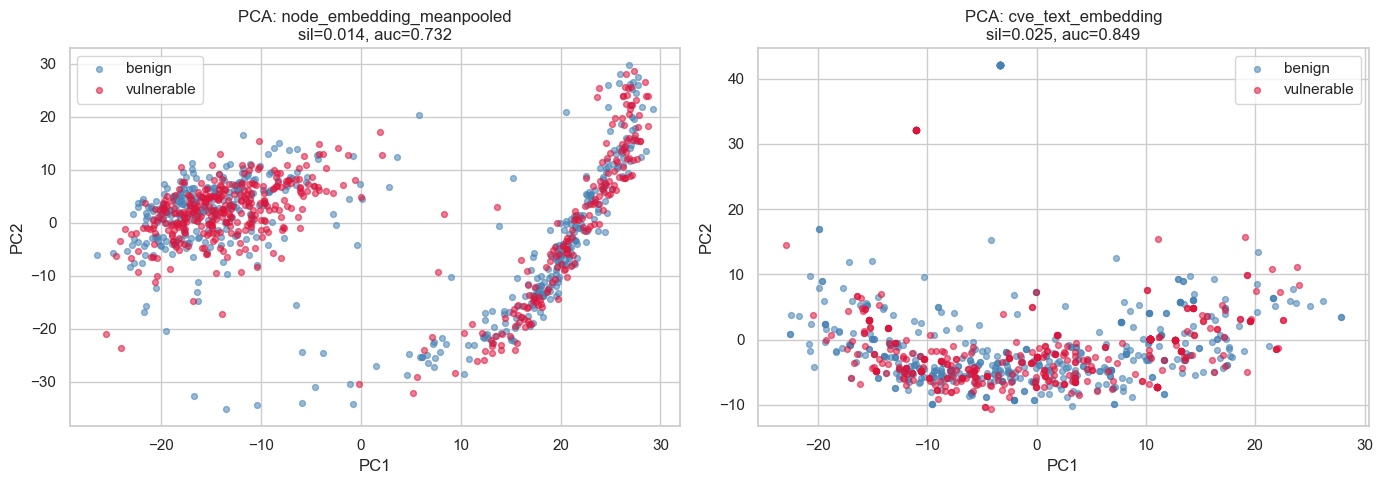

In [15]:
node_embedding_matrix, cve_text_embedding_matrix, embedding_labels = ensure_embedding_inputs(
    dataset,
    fallback_labels=structural_features_df["label"].to_numpy(),
)

embedding_diagnostics = {
    "node_embedding_meanpooled": compute_embedding_diagnostics(node_embedding_matrix, embedding_labels),
    "cve_text_embedding": compute_embedding_diagnostics(cve_text_embedding_matrix, embedding_labels),
}

embedding_diagnostics_table = pd.DataFrame(
    {
        name: {
            key: diagnostics.get(key)
            for key in [
                "dim",
                "pc1_var",
                "pc2_var",
                "silhouette",
                "centroid_distance",
                "logistic_acc",
                "logistic_auc",
                "logistic_f1",
                "nn_agreement",
            ]
        }
        for name, diagnostics in embedding_diagnostics.items()
        if diagnostics is not None
    }
).T.round(4)

display(embedding_diagnostics_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, diagnostics) in zip(axes, embedding_diagnostics.items()):
    if diagnostics is None:
        ax.set_title(f"{name} unavailable")
        ax.axis("off")
        continue
    proj = diagnostics["projection"]
    labels_for_plot = diagnostics["labels"]
    for label_value, label_name in LABEL_NAME_MAP.items():
        mask = labels_for_plot == label_value
        if mask.sum() == 0:
            continue
        ax.scatter(
            proj[mask, 0],
            proj[mask, 1],
            s=18,
            alpha=0.55,
            label=label_name,
            color=PLOT_COLORS[label_name],
        )
    ax.set_title(
        f"PCA: {name}\n"
        f"sil={diagnostics['silhouette']:.3f}, auc={diagnostics['logistic_auc']:.3f}"
        if pd.notna(diagnostics["silhouette"]) and pd.notna(diagnostics["logistic_auc"])
        else f"PCA: {name}"
    )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend()
plt.tight_layout()
plt.show()


### F. Optional Correlation Check

This correlation view checks whether graph size or edge-type composition tracks the label directly.

Why it matters:
- Strong correlations do not prove causality, but they can reveal proxy features that a model could exploit.
- Relationships among node count, edge count, and density also help explain any label or split differences seen above.

Interpretation:
- Positive or negative correlation with the encoded label suggests that the feature may carry class signal.
- Strong correlation among structural features can indicate redundancy, which is useful context when designing ablations.


,num_nodes,num_edges,edge_density_like,ast_ratio,cfg_ratio,pdg_ratio,label
num_nodes,1.000,0.958,0.634,-0.557,-0.398,0.467,0.270
num_edges,0.958,1.000,0.595,-0.551,-0.335,0.421,0.242
edge_density_like,0.634,0.595,1.000,-0.938,-0.912,0.954,0.227
ast_ratio,-0.557,-0.551,-0.938,1.000,0.847,-0.930,-0.185
cfg_ratio,-0.398,-0.335,-0.912,0.847,1.000,-0.983,-0.130
pdg_ratio,0.467,0.421,0.954,-0.930,-0.983,1.000,0.154
label,0.270,0.242,0.227,-0.185,-0.130,0.154,1.000


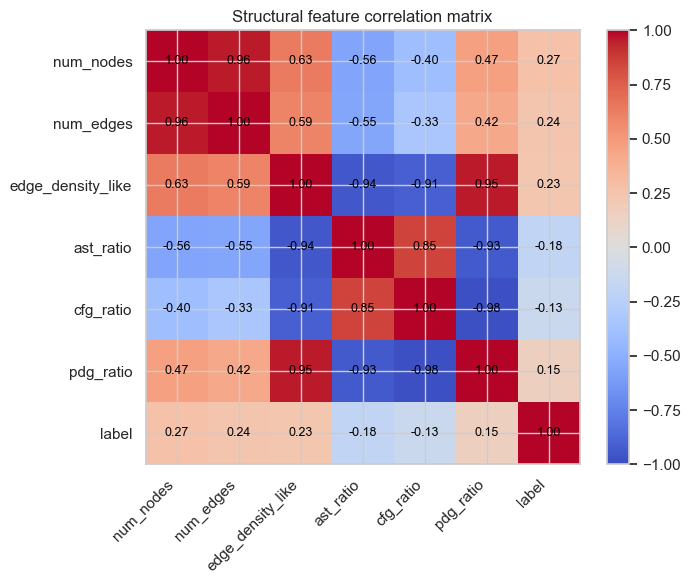

In [16]:
correlation_features = [
    "num_nodes",
    "num_edges",
    "edge_density_like",
    "ast_ratio",
    "cfg_ratio",
    "pdg_ratio",
    "label",
]
correlation_features = [feature for feature in correlation_features if feature in structural_features_df.columns]

if len(correlation_features) >= 2:
    structural_correlation_matrix = structural_features_df[correlation_features].corr(numeric_only=True)
    display(structural_correlation_matrix.round(3))

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(structural_correlation_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(np.arange(len(structural_correlation_matrix.columns)))
    ax.set_xticklabels(structural_correlation_matrix.columns, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(structural_correlation_matrix.index)))
    ax.set_yticklabels(structural_correlation_matrix.index)
    for row_idx in range(structural_correlation_matrix.shape[0]):
        for col_idx in range(structural_correlation_matrix.shape[1]):
            ax.text(
                col_idx,
                row_idx,
                f"{structural_correlation_matrix.iloc[row_idx, col_idx]:.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=9,
            )
    ax.set_title("Structural feature correlation matrix")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()
else:
    structural_correlation_matrix = pd.DataFrame()
    print("Skipping correlation matrix: not enough numeric structural features are available.")


### Summary Template

Fill this in after reviewing the outputs above:
- Structural differences by label:
- Split comparability:
- Outlier risks:
- Graph vs text embedding signal:
